In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error, root_mean_squared_error, r2_score)
import matplotlib.pyplot as plt

# Load features dataset
df = pd.read_csv("../../data/processed/white_wine_features.csv")

# Separate features from target. Remove alcohol_density_ratio column.
X = df.drop(["quality", "alcohol_density_ratio"], axis=1)
y = df["quality"]

# Create the model
model = RandomForestRegressor(random_state=42)

# Train, test, split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the model 
model.fit(X_train, y_train)



,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [2]:


# Tune the model hyperparameters
# Define the parameter grid
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

# Create GridSearchCV object
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

# Fit the grid search
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 10, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,

In [3]:
print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}


In [4]:
print("Best CV R²:", grid_search.best_score_)

Best CV R²: 0.37300918355932183


In [5]:
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

print(f"R²: {r2_score(y_test, y_pred):.3f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred):.3f}")
print(f"RMSE: {root_mean_squared_error(y_test, y_pred):.3f}")

R²: 0.337
MAE: 0.564
RMSE: 0.737


In [6]:
importance = pd.Series(
    best_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance)

alcohol                 0.266317
volatile acidity        0.122324
free sulfur dioxide     0.098383
so2_ratio               0.069840
pH                      0.067774
fixed acidity           0.057249
residual sugar          0.056582
total sulfur dioxide    0.055072
chlorides               0.053572
sulphates               0.051744
citric acid             0.051648
density                 0.049496
dtype: float64


#### Feature Importance

The feature importances produced by the Random Forest Regressor indicate that **alcohol** is the most influential predictor of wine quality, followed by **sulphates** and **volatile acidity**. These findings are consistent with the exploratory data analysis, where alcohol showed the strongest positive correlation with the target variable.

The engineered feature **`so2_ratio`** ranked fifth in importance, ahead of several original physicochemical variables, including density, pH, fixed acidity, citric acid, and free sulfur dioxide. This supports the earlier modeling results, which showed a small but consistent improvement in predictive performance when `so2_ratio` was included.

Overall, the feature importance analysis suggests that the engineered `so2_ratio` feature contributes meaningful predictive information and justifies its inclusion in the final Random Forest model.


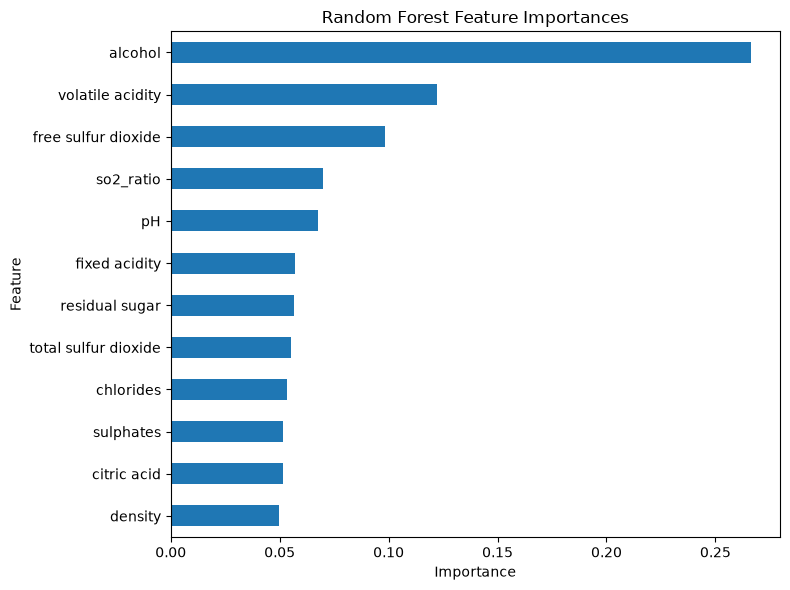

In [7]:
# Create a bar chart
plt.figure(figsize=(8, 6))
importance.plot(kind="barh")
plt.gca().invert_yaxis()

plt.title("Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()

# Save the figure
plt.savefig("../../assets/white_random_forest_feature_importance.png", dpi=300, bbox_inches="tight")

plt.show()

In [8]:
# Save the model
import joblib

joblib.dump(best_model, "../../models/best_random_forest_white_wine.pkl")

['../../models/best_random_forest_white_wine.pkl']

#### Hyperparameter Tuning

A five-fold `GridSearchCV` evaluated combinations of the Random Forest Regressor’s tree count, maximum depth, minimum split size, and minimum leaf size. The best-performing configuration used 200 trees, a maximum depth of 20, a minimum split size of 5, and a minimum leaf size of 2.

On the test set, the tuned model achieved an R² of 0.337, an MAE of 0.564, and an RMSE of 0.737. Compared with the untuned Random Forest, these are small improvements: R² increased from 0.326, while MAE and RMSE decreased from 0.569 and 0.743. The tuned model also slightly outperformed the untuned Gradient Boosting model (R² 0.335, MAE 0.576, RMSE 0.739) on all three reported metrics. The differences are narrow, however, so they suggest a modest improvement—not a substantial increase in predictive accuracy.

An R² of 0.337 means the model accounts for about 34% of the variation in wine quality. Its average absolute prediction error is about 0.56 quality points. Together, these results indicate useful but limited predictive performance.

Alcohol, sulphates, and volatile acidity remained the three most influential features, and the engineered `so2_ratio` ranked among the five most important. Feature importance describes how the fitted model uses its predictors; it does not establish that a feature causes changes in wine quality or independently improves accuracy. Since `so2_ratio` produced only a marginal improvement in the earlier model comparison, it may largely represent information already present in the sulfur dioxide measurements.

The tuned Random Forest had the strongest reported test-set metrics among the models compared, but its advantage over Gradient Boosting was slight. It was selected as the final model, with the results suggesting modest predictive gains rather than a decisive improvement.